# Experiment 02 - CNN with Data Augmentation

In this experiment, we add data augmentation to the baseline CNN.

Only the training transform is changed.
The model architecture, loss function, optimizer, validation split,
and other training settings remain the same as the baseline.

### Goal:
Evaluate whether data augmentation improves validation performance
and reduces overfitting.

### Experimental setup

- Number of classes: 8
- Input size: 224 × 224
- Validation split: 80/20
- Random seed: 42
- Batch size: 32
- Loss function: Cross-Entropy Loss
- Optimizer: Adam
- Learning rate: 1e-3
- Data augmentation: Yes
- Dropout: None
- Global Average Pooling: None

The validation set is used for model comparison and checkpoint selection.
The test set remains frozen and is not used during model development.

In [12]:
import sys
from pathlib import Path
from torchvision import datasets
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import math
import json

from torch.optim import Adam
from torchvision import transforms

from sklearn.metrics import classification_report

# Project root
PROJECT_DIR = Path.cwd().parent

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

sys.path.append("../src")

from data import (
    letterbox,
    create_train_val_datasets,
    create_dataloaders
)

from models import SimpleCNN

from train import train_model

from utils import (
    get_predictions,
    plot_confusion_matrix,
    get_classification_report,
    plot_training_history,
    set_seed
)

### Configuration

In [13]:
SEED = 42
set_seed(SEED)
BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 1e-3
NUM_CLASSES = 8


config = {
    "model" : "SimpleCNN",
    "experiment": "Augmentation",
    "num_classes": NUM_CLASSES,
    "dropout": 0.0,
    "use_gap": False,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "epochs": EPOCHS,

    "train_transform": [
        "letterbox",
        "Resize(224,224)",
        "RandomHorizontalFlip(p=0.5)",
        "RandomRotation(10)",
        "ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2)",
        "ToTensor",
        "Normalize"
    ],

    "val_transform": [
        "letterbox",
        "Resize(224,224)",
        "ToTensor",
        "Normalize"
    ]
}


DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

Device: cpu


### Paths

In [14]:
MERGED_TRAIN_DIR = PROJECT_DIR / "dataset" / "merged_train"
TEST_DIR = PROJECT_DIR / "dataset" / "test"

print("Training directory:", MERGED_TRAIN_DIR)
print("Test directory:", TEST_DIR)

print("Training directory exists:", MERGED_TRAIN_DIR.exists())
print("Test directory exists:", TEST_DIR.exists())

Training directory: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\merged_train
Test directory: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\test
Training directory exists: True
Test directory exists: True


### Transforms

In [15]:
train_transform = transforms.Compose([
    transforms.Lambda(
        lambda img: letterbox(
            img,
            target_size=(224, 224)
        )
    ),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(10),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ***********

val_transform = transforms.Compose([
    transforms.Lambda(
        lambda img: letterbox(
            img,
            target_size=(224, 224)
        )
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

### Create Train/Validation Datasets

In [16]:
train_dataset, val_dataset, train_indices, val_indices,_ = \
    create_train_val_datasets(
        data_dir=MERGED_TRAIN_DIR,
        train_transform=train_transform,
        val_transform=val_transform,
        test_size=0.2,
        seed=SEED
    )

### Class Names

In [17]:
full_dataset = datasets.ImageFolder(
    MERGED_TRAIN_DIR
)

class_names = full_dataset.classes
class_to_idx = full_dataset.class_to_idx

print("Classes:")
for index, class_name in enumerate(class_names):
    print(index, "->", class_name)

print("\nNumber of classes:", len(class_names))

Classes:
0 -> ambulance
1 -> autobus
2 -> kamyun
3 -> kamyunet
4 -> minibus
5 -> savari
6 -> taxi
7 -> vanet

Number of classes: 8


### DataLoader

In [18]:
train_loader, val_loader = create_dataloaders(
    train_dataset=train_dataset,
    val_dataset=val_dataset,
    batch_size=BATCH_SIZE,
    shuffle_train=True
)

print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))

Number of training batches: 85
Number of validation batches: 22


### Checking one Batch

Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Labels: tensor([1, 0, 0, 3, 6, 4, 1, 0, 3, 2, 2, 6, 6, 2, 2, 5, 4, 5, 1, 6, 5, 0, 0, 3,
        2, 3, 6, 5, 2, 0, 2, 4])


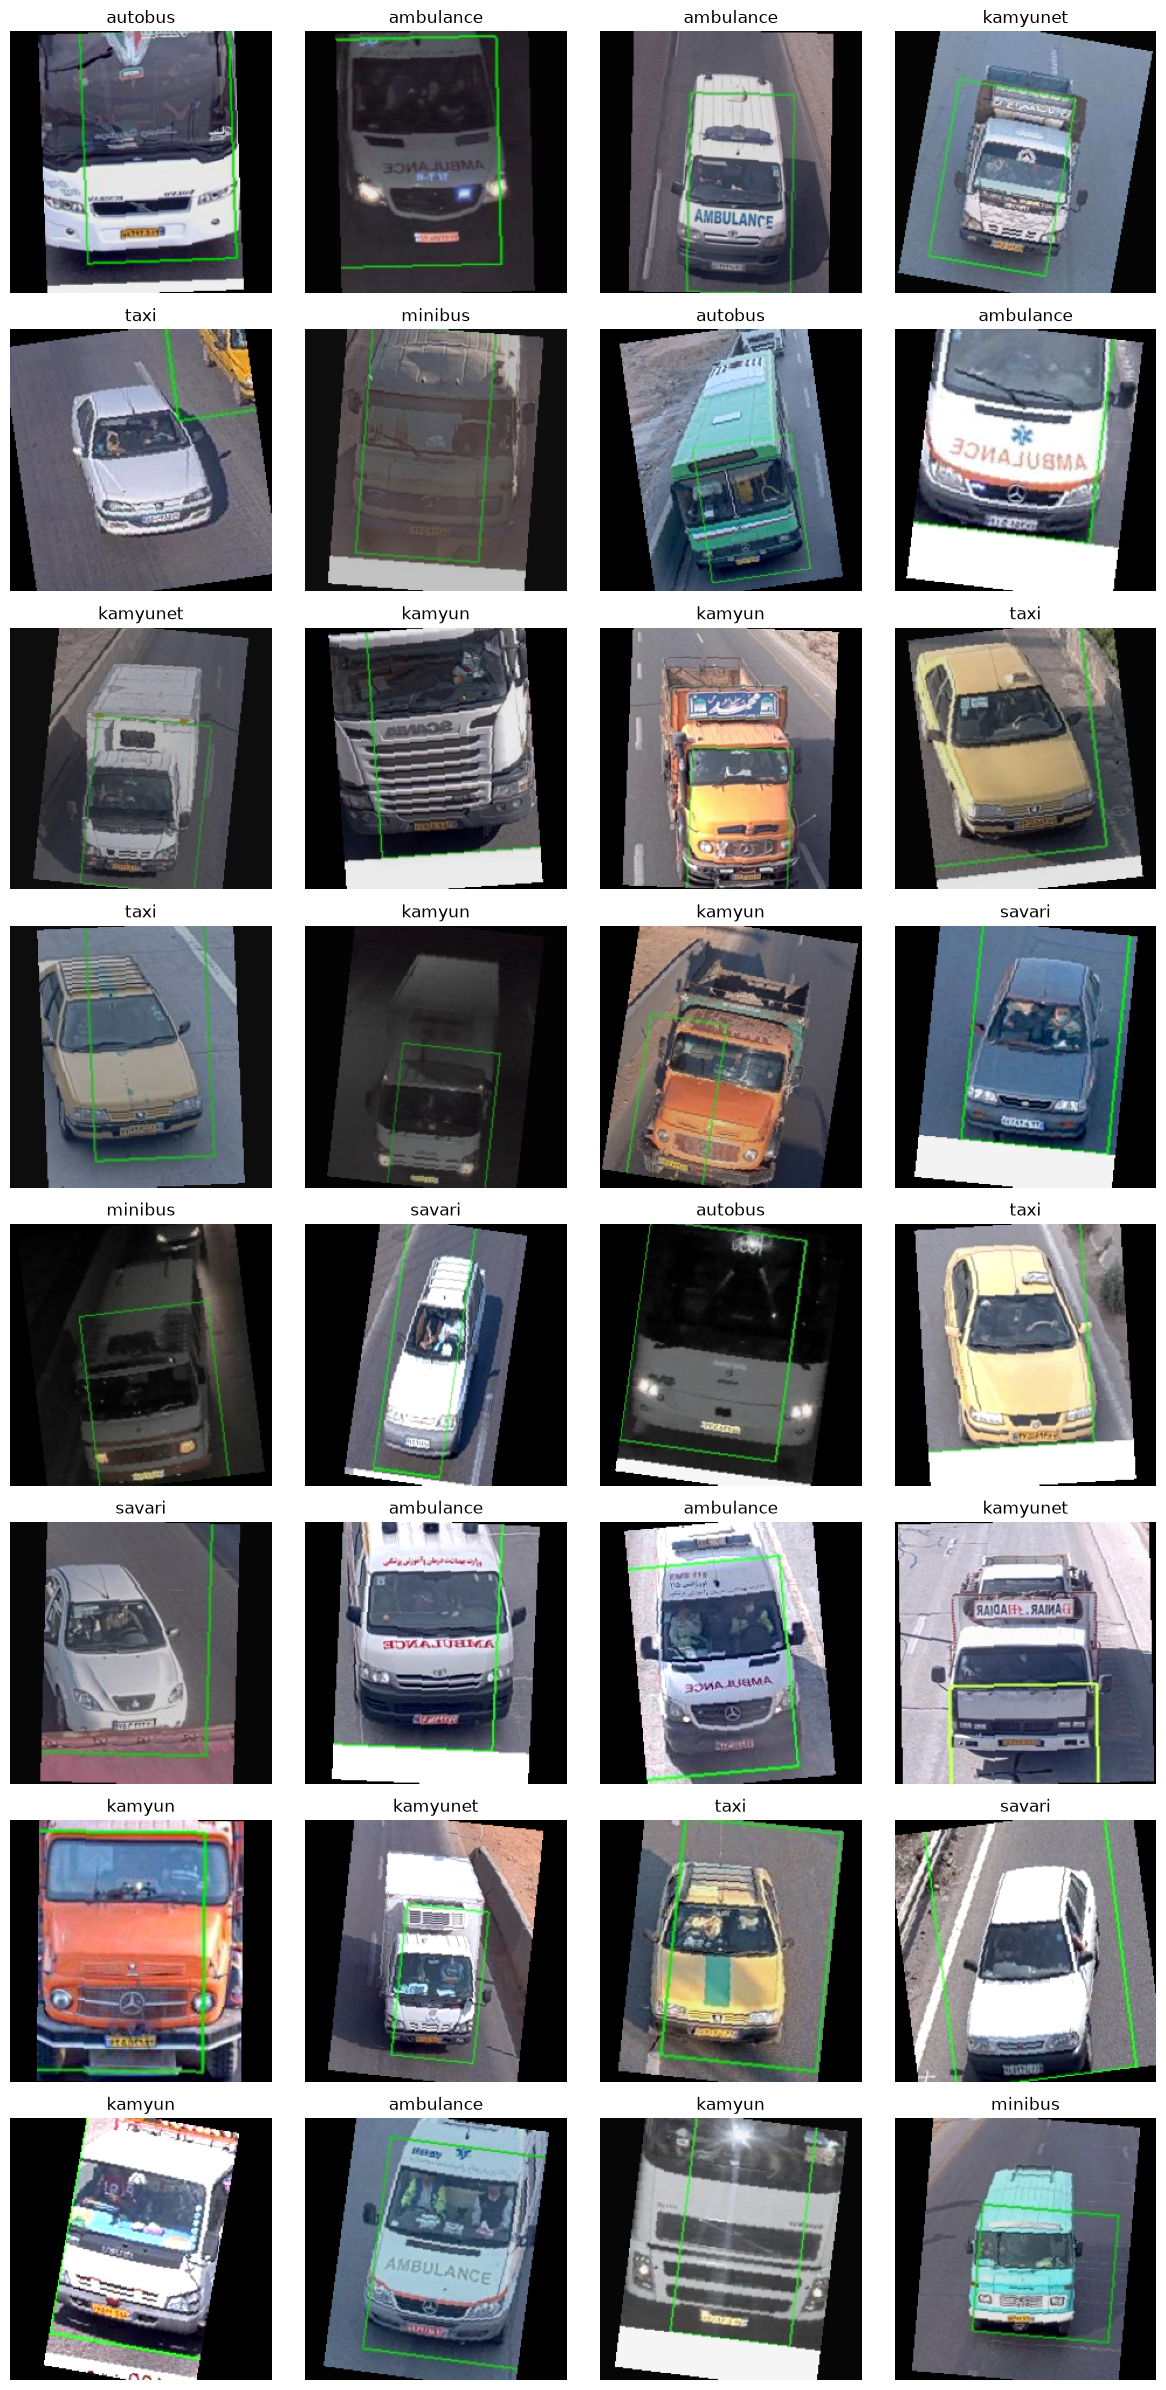

In [19]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels)

# ImageNet normalization values
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

num_images = len(images)
cols = 4
rows = math.ceil(num_images / cols)

plt.figure(figsize=(12, 3 * rows))

for i in range(num_images):
    # Denormalize
    image = images[i] * std + mean

    # CHW -> HWC
    image = image.permute(1, 2, 0)

    # Keep values in valid display range
    image = image.clamp(0, 1)

    plt.subplot(rows, cols, i + 1)
    plt.imshow(image)
    plt.title(class_names[labels[i].item()])
    plt.axis("off")

plt.tight_layout()
plt.show()

### Augmented CNN Model

In [20]:
model = SimpleCNN(
    num_classes=NUM_CLASSES,
    dropout=0.00,
    use_gap=False
)


model = model.to(DEVICE)

print(model)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): Identity()
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=200704, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
    (4): Linear(in_features=128, out_features=8, bias=True)
  )
)


### Loss and Optimizer

In [21]:
criterion = nn.CrossEntropyLoss()

optimizer = Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

### Train

In [22]:
history, best_val_accuracy = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        criterion=criterion,
        optimizer=optimizer,
        device=DEVICE,
        epochs=EPOCHS,
        model_name="augmentation",
        class_to_idx=class_to_idx,
        seed=SEED,
        config=config
    )
print("Best validation accuracy:", best_val_accuracy)

Epoch [1/10] Train Loss: 2.0642 --- Train Acc: 0.4408 --- Val Loss: 1.0897 --- Val Acc: 0.6171
Epoch [2/10] Train Loss: 1.0043 --- Train Acc: 0.6554 --- Val Loss: 0.8591 --- Val Acc: 0.6907
Epoch [3/10] Train Loss: 0.8162 --- Train Acc: 0.7258 --- Val Loss: 0.8588 --- Val Acc: 0.7143
Epoch [4/10] Train Loss: 0.6896 --- Train Acc: 0.7637 --- Val Loss: 0.8151 --- Val Acc: 0.7378
Epoch [5/10] Train Loss: 0.6031 --- Train Acc: 0.7921 --- Val Loss: 0.7747 --- Val Acc: 0.7349
Epoch [6/10] Train Loss: 0.5024 --- Train Acc: 0.8286 --- Val Loss: 0.7300 --- Val Acc: 0.7614
Epoch [7/10] Train Loss: 0.4548 --- Train Acc: 0.8397 --- Val Loss: 0.7165 --- Val Acc: 0.7673
Epoch [8/10] Train Loss: 0.3998 --- Train Acc: 0.8673 --- Val Loss: 0.7052 --- Val Acc: 0.7673
Epoch [9/10] Train Loss: 0.3333 --- Train Acc: 0.8802 --- Val Loss: 0.7966 --- Val Acc: 0.7761
Epoch [10/10] Train Loss: 0.3059 --- Train Acc: 0.8876 --- Val Loss: 0.7244 --- Val Acc: 0.7791

Best checkpoint saved:
D:\AI Bootcamp_M Sharif\t

### Training Curves

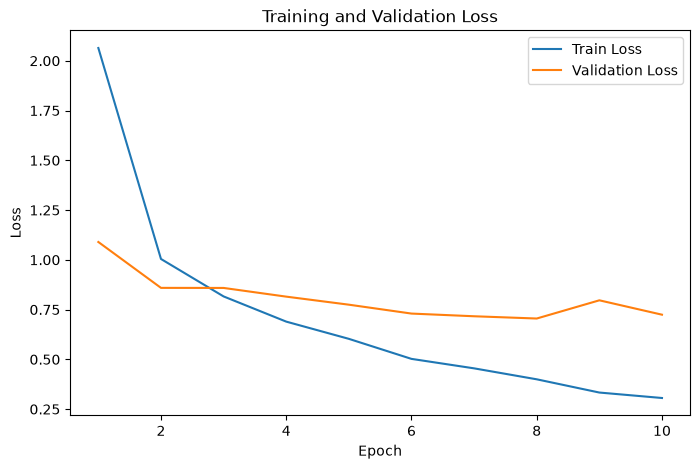

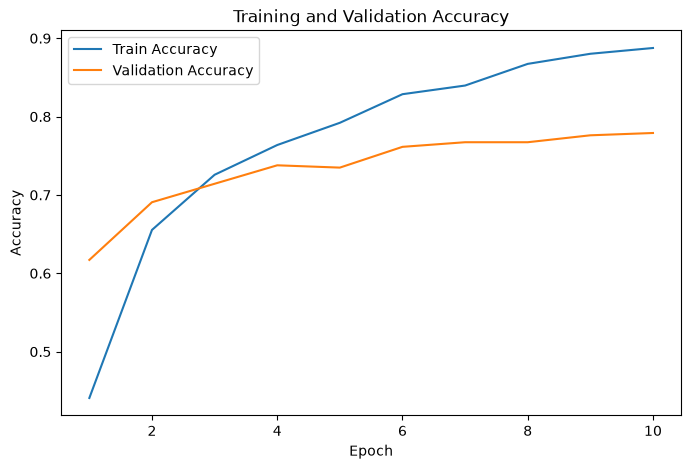

In [23]:
plot_training_history(history=history)

### Best Epoch

In [35]:
best_epoch = np.argmax(
    history["val_accuracy"]
) + 1

print("Best epoch:", best_epoch)
print("Best validation accuracy:", best_val_accuracy)

Best epoch: 10
Best validation accuracy: 0.7790868924889544


### Load Best Checkpoint

In [34]:
checkpoint_path = (
    PROJECT_DIR
    / "checkpoints"
    / "augmentation_best.pt"
)


checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

print("Best epoch:", checkpoint["epoch"])
print(
    "Best validation accuracy:",
    checkpoint["val_accuracy"]
)

Best epoch: 10
Best validation accuracy: 0.7790868924889544


### Validation Prediction

In [26]:
true_labels, predictions = get_predictions(
    model=model,
    loader=val_loader,
    device=DEVICE
)

print("Number of  validation predictions:", len(predictions))
correct = (true_labels == predictions).sum()
print("Number of correct validation predictions:", correct)
accuracy = correct / len(predictions)
print("Validation accuracy:", accuracy)

Number of  validation predictions: 679
Number of correct validation predictions: 529
Validation accuracy: 0.7790868924889544


### Classification Report

In [27]:
report = get_classification_report(
    model=model,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE
)

              precision    recall  f1-score   support

   ambulance     0.8250    0.9041    0.8627        73
     autobus     0.8763    0.9043    0.8901        94
      kamyun     0.5877    0.6768    0.6291        99
    kamyunet     0.6712    0.5385    0.5976        91
     minibus     0.8125    0.7927    0.8025        82
      savari     0.7589    0.8500    0.8019       100
        taxi     1.0000    0.9293    0.9634        99
       vanet     0.6452    0.4878    0.5556        41

    accuracy                         0.7791       679
   macro avg     0.7721    0.7604    0.7628       679
weighted avg     0.7803    0.7791    0.7768       679



### Confusion Matrix

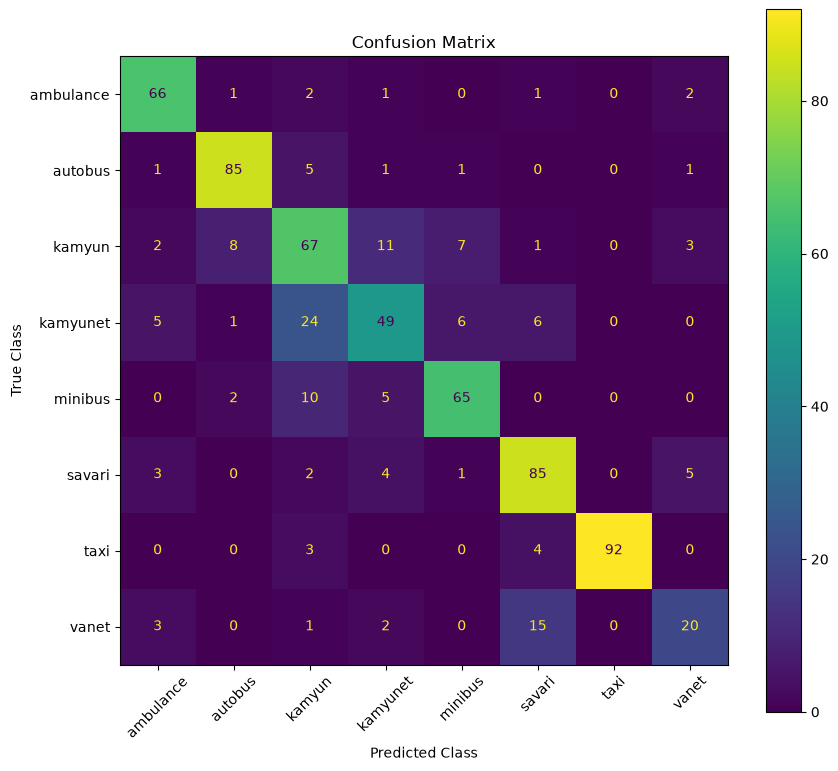

In [28]:
cm = plot_confusion_matrix(
    model=model,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE
)

### Normalized Confusion Matrix

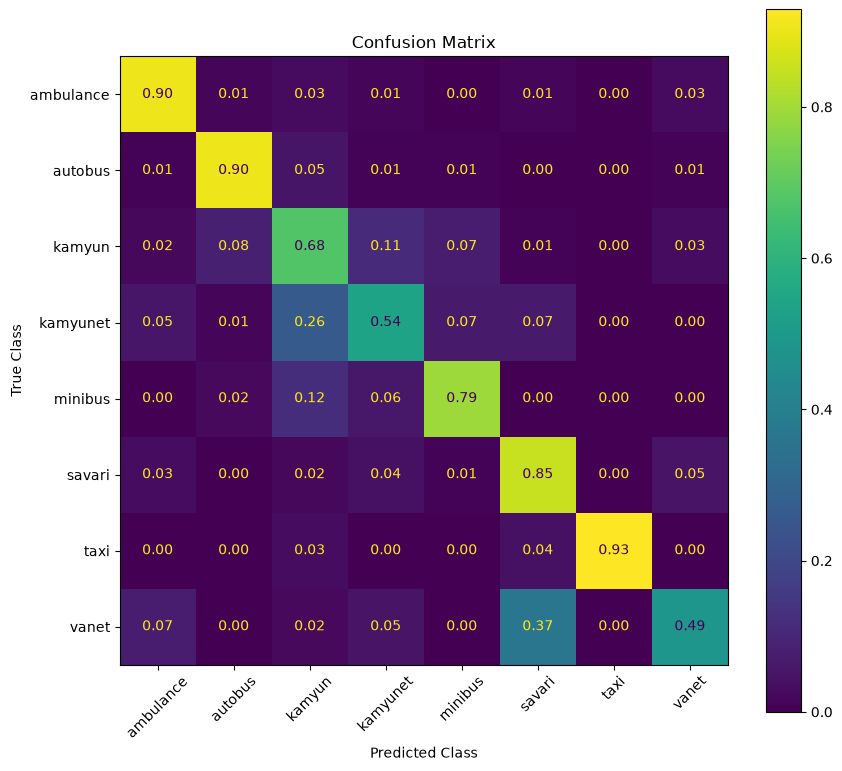

In [29]:
cm_normalized = plot_confusion_matrix(
    model=model,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE,
    normalize="true"
)

### Train/Valditaion Gap

In [38]:
best_epoch = np.argmax(
    history["val_accuracy"]
)

best_train_accuracy = history["train_accuracy"][best_epoch]
best_val_accuracy = history["val_accuracy"][best_epoch]

print("Best Epoch:", best_epoch + 1)

print(
    "Best Train Accuracy:",
    best_train_accuracy
)

print(
    "Best Validation Accuracy:",
    best_val_accuracy
)

print(
    "Train-Validation Gap:",
    best_train_accuracy - best_val_accuracy
)

Best Epoch: 10
Best Train Accuracy: 0.8875783265757464
Best Validation Accuracy: 0.7790868924889544
Train-Validation Gap: 0.10849143408679207


### Augmented CNN Result

In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

augmentation_accuracy = accuracy_score(
    true_labels,
    predictions
)

augmentation_precision = precision_score(
    true_labels,
    predictions,
    average="macro",
    zero_division=0
)

augmentation_recall = recall_score(
    true_labels,
    predictions,
    average="macro",
    zero_division=0
)

augmentation_f1 = f1_score(
    true_labels,
    predictions,
    average="macro",
    zero_division=0
)

print("Augmentation Validation Results")
print("---------------------------")
print("Accuracy:", augmentation_accuracy)
print("Macro Precision:", augmentation_precision)
print("Macro Recall:", augmentation_recall)
print("Macro F1:", augmentation_f1)

Augmentation Validation Results
---------------------------
Accuracy: 0.7790868924889544
Macro Precision: 0.7721038370628637
Macro Recall: 0.7604218571987782
Macro F1: 0.7628410850052175


## Final Comparision Augmentation Vs Non Augmentation

In [32]:
PROJECT_DIR = Path.cwd().parent
RESULTS_FILE = PROJECT_DIR / "results" / "experiment_results.json"

with open(RESULTS_FILE, "r", encoding="utf-8") as f:
    results = json.load(f)
    
# Non Augmentation
baseline_result = results["baseline_cnn"]

print("Non Augmentation Results")
print("----------------")
print("Best Epoch:", baseline_result["best_epoch"])
print("Best Validation Accuracy:", baseline_result["best_val_accuracy"])
print("Validation Loss at Best Epoch:", baseline_result["best_val_loss"])
print("*" * 30)

# Augmentation
augmentation_result = results["augmentation"]

print("Augmentation Results")
print("------------------")
print("Best Epoch:", augmentation_result["best_epoch"])
print("Best Validation Accuracy:", augmentation_result["best_val_accuracy"])
print("Validation Loss at Best Epoch:", augmentation_result["best_val_loss"])


Non Augmentation Results
----------------
Best Epoch: 9
Best Validation Accuracy: 0.7893961708394698
Validation Loss at Best Epoch: 1.1164248662072183
******************************
Augmentation Results
------------------
Best Epoch: 10
Best Validation Accuracy: 0.7790868924889544
Validation Loss at Best Epoch: 0.7244209195206022
